# Evaluation of Fuzzy Method / Model

expliquer en vif le projet 

## Data

TODO : deux tableaux avec des réponses à nos questions (profile et travel), adapter les réponses pour avoir des recommendation différentes à la fin 

TODO : un excel avec plusieurs destinations (maybe que focus sur l'europe pour l'instant) avec des scores qui correspondent aux valeurs crisp des réponses

Présenter les tableaux et expliquer ce qu'on attend comme résultats pour les utilisateurs

Expliquation des tableaux :
* donner les topics
* donner les questions
* donner les priority et leur justifications (pour profile et pour travel)

(potentiellement juste donner les pages du pdf pour les questions, topics et priorities puis justifier en text)


Expliquer les résultats en se basant sur les valeurs des destinations -> se baser sur les valeurs des destinations pour biaiser les réponse fictives des questionnaires

### Data Preprocessing

Adapter les valeurs fuzzy en crisp pour les tableaux des questionnaires

Faire en sorte que ça s'adapte aussi pour les teste avec un user pour l'évaluation en "User Testing"

### 1.

In [16]:
%pip install numpy pandas

Note: you may need to restart the kernel to use updated packages.


In [17]:
import numpy as np
import pandas as pd

# Load our dataset
cities = pd.read_csv("Cities.csv")

# Themes with at least one questionnaire question
selected_themes = [
    1, 2, 3, 4, 6, 7, 8, 12, 13, 14,
    17, 18, 19, 20, 21, 22, 23, 24, 27
]

selected_columns = [
    f"t{theme}" for theme in selected_themes
]

# We keep only relevant criteria
cities_selected = cities[
    ["City"] + selected_columns
].copy()

print("Number of destinations:", len(cities_selected))
print("Number of themes:", len(selected_columns))
print("Missing values:", cities_selected.isna().sum().sum())

display(cities_selected.head())


Number of destinations: 41
Number of themes: 19
Missing values: 0


,City,t1,t2,t3,t4,t6,t7,t8,t12,t13,t14,t17,t18,t19,t20,t21,t22,t23,t24,t27
0,Amsterdam,6,6,3,2,4,9,6,6,2,4,4,1,4,6,4,2,9,3,4
1,Barcelona,6,9,3,2,6,6,4,6,4,4,4,2,3,4,4,6,6,3,4
2,Berlin,9,6,4,3,6,9,6,9,2,4,6,3,4,6,4,2,9,4,6
3,Bratitslava,3,3,4,4,3,4,4,3,3,4,4,6,4,4,3,3,4,2,6
4,Bruge,2,4,6,4,6,4,6,2,4,3,3,2,4,4,4,3,3,2,6


## 2. questionnaire input types

In [18]:

# Questionnaire input types for each selected theme

question_types = {
    "t1":  {"P": None, "T": "scale_7"},
    "t2":  {"P": "slider_100", "T": None},
    "t3":  {"P": "categorical", "T": None},
    "t4":  {"P": "slider_100", "T": "slider_100"},
    "t6":  {"P": None, "T": "scale_7"},
    "t7":  {"P": "scale_7", "T": None},
    "t8":  {"P": "scale_7", "T": None},
    "t12": {"P": "slider_100", "T": "scale_7"},
    "t13": {"P": "slider_100", "T": "multiple_choice"},
    "t14": {"P": "scale_7", "T": "scale_7"},
    "t17": {"P": "scale_7", "T": None},
    "t18": {"P": "scale_7", "T": "budget"},
    "t19": {"P": "scale_7", "T": None},
    "t20": {"P": "scale_7", "T": None},
    "t21": {"P": "scale_7", "T": "scale_5"},
    "t22": {"P": "categorical", "T": "categorical"},
    "t23": {"P": "scale_7", "T": "multiple_choice"},
    "t24": {"P": "scale_7", "T": "scale_5"},
    "t27": {"P": None, "T": "multiple_choice"}
}

# Check if all selected themes are represented
assert set(question_types) == set(selected_columns)

print("Number of themes:", len(question_types))

print(
    "Personality questions:",
    sum(q["P"] is not None for q in question_types.values())
)

print(
    "Trip questions:",
    sum(q["T"] is not None for q in question_types.values())
)


Number of themes: 19
Personality questions: 16
Trip questions: 12


### 3. Reference answer

In [19]:

from copy import deepcopy

# Default Personality Test answers
base_personality = {
    "t2": 50,                  # Gastronomy (0-100)
    "t3": "Combination",      # Authenticity
    "t4": 50,                  # Relaxation (0-100%)
    "t7": 4,                   # Infrastructure (1-7)
    "t8": 4,                   # Hygiene precautions (1-7)
    "t12": 50,                 # Unique experiences (0-100)
    "t13": 50,                 # Natural landscapes (0-100)
    "t14": 4,                  # Travel pace (1-7)
    "t17": 4,                  # Flexibility (1-7)
    "t18": 4,                  # Price sensitivity (1-7)
    "t19": 6,                  # Personal safety (1-7)
    "t20": 6,                  # Healthcare (1-7)
    "t21": 4,                  # Accommodation comfort (1-7)
    "t22": "Mild",             # Climate preference
    "t23": 4,                  # Transport effort tolerance (1-7)
    "t24": 4                   # Physical activity (1-7)
}

# Default Trip Questionnaire answers
base_trip = {
    "t1": 4,                   # Change of scenery (1-7)
    "t4": 50,                  # Relaxation (0-100%)
    "t6": 4,                   # Landmarks (1-7)
    "t12": 4,                  # Unique experiences (1-7)
    "t13": ["Mountains", "Beaches"],
    "t14": 4,                  # Travel pace (1-7)
    "t18": {
        "preferred": 1800,
        "maximum": 2500
    },                        # Budget in CHF
    "t21": 3,                  # Accommodation comfort (1-5)
    "t22": "Mild",             # Climate
    "t23": ["Walking", "Public transport"],
    "t24": 3,                  # Physical activity (1-5)
    "t27": ["Quality time"]
}


### 4. Initialize four profiles


Here we created four snthetic taveler profiles to evaluate our fuzzy recommendation system.
- Adventure lover
- Relaxation lover
- Food Explorer
- Balanced Traveler

Each traveler answers the questions from the personality test and trip questionnaire.
We use 19 themes. The goal is to check whether our system produces logical and consistent destination recommendations for different traveler preferences.

In [20]:

# Initialize the four scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler"
]

personality_answers = {
    name: deepcopy(base_personality)
    for name in scenario_names
}

trip_answers = {
    name: deepcopy(base_trip)
    for name in scenario_names
}

# Scenario 1: Adventure Lover
personality_answers["Adventure Lover"].update({
    "t2": 35,
    "t3": "Local life",
    "t4": 15,
    "t7": 6,
    "t12": 90,
    "t13": 90,
    "t14": 7,
    "t17": 6,
    "t21": 3,
    "t22": "Cool",
    "t23": 6,
    "t24": 7
})

trip_answers["Adventure Lover"].update({
    "t1": 7,
    "t4": 10,
    "t6": 3,
    "t12": 7,
    "t13": ["Mountains", "Forests"],
    "t14": 7,
    "t18": {"preferred": 1600, "maximum": 2200},
    "t21": 2,
    "t22": "Mild",
    "t23": ["Walking", "Bicycle"],
    "t24": 5,
    "t27": ["Group activities"]
})

# Scenario 2: Relaxation Lover
personality_answers["Relaxation Lover"].update({
    "t2": 40,
    "t4": 85,
    "t7": 2,
    "t8": 2,
    "t12": 25,
    "t13": 80,
    "t14": 1,
    "t17": 2,
    "t21": 7,
    "t22": "Warm",
    "t23": 2,
    "t24": 1
})

trip_answers["Relaxation Lover"].update({
    "t1": 3,
    "t4": 90,
    "t6": 2,
    "t12": 2,
    "t13": ["Beaches", "Lakes"],
    "t14": 1,
    "t18": {"preferred": 2000, "maximum": 3000},
    "t21": 5,
    "t22": "Warm",
    "t23": ["Car", "Public transport"],
    "t24": 1,
    "t27": ["Quality time"]
})

# Scenario 3: Food Explorer
personality_answers["Food Explorer"].update({
    "t2": 95,
    "t3": "Local life",
    "t4": 35,
    "t12": 75,
    "t13": 45,
    "t14": 5,
    "t17": 5,
    "t18": 5,
    "t22": "Warm",
    "t24": 3
})

trip_answers["Food Explorer"].update({
    "t1": 6,
    "t4": 30,
    "t6": 6,
    "t12": 6,
    "t13": ["Countryside"],
    "t14": 5,
    "t18": {"preferred": 2200, "maximum": 3000},
    "t22": "Warm",
    "t23": ["Walking", "Public transport"],
    "t24": 2,
    "t27": ["Meeting new people", "Quality time"]
})

print("Synthetic profiles created successfully!")
print("Number of scenarios:", len(scenario_names))


Synthetic profiles created successfully!
Number of scenarios: 4


### 5. Additional test scenarios


To further evaluate the fuzzy recommendation system, we added three scenarios:

- **Adventurer Seeking Relaxation:** A traveler who usually enjoys adventure but wants a relaxing vacation this time.
- **Budget-Constrained Traveler:** A traveler with a limited maximum budget.
- **Adventure Preference Change:** A traveler whose desired adventure level changes while all other preferences remain the same.

These scenarios help us test whether the system adapts to changing trip preferences, respects budget constraints, and behaves consistently when a single input is modified.


In [21]:

from copy import deepcopy

# Scenario 5: Adventurer Seeking Relaxation
name = "Adventurer Seeking Relaxation"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# only change current trip preferences
trip_answers[name].update({
    "t4": 90,     # High relaxation
    "t14": 1,     # Very relaxed travel pace
    "t24": 1      # Very low physical activity
})


# Scenario 6: Budget-Constrained Traveler
name = "Budget-Constrained Traveler"

personality_answers[name] = deepcopy(
    personality_answers["Balanced Traveler"]
)

trip_answers[name] = deepcopy(
    trip_answers["Balanced Traveler"]
)

# only change the budget
trip_answers[name]["t18"] = {
    "preferred": 500,
    "maximum": 700
}


# Scenario 7: Adventure Preference Change
name = "Adventure Preference Change"

personality_answers[name] = deepcopy(
    personality_answers["Adventure Lover"]
)

trip_answers[name] = deepcopy(
    trip_answers["Adventure Lover"]
)

# Here we change only one variable
trip_answers[name]["t24"] = 1


# Update the list of scenarios
scenario_names = [
    "Adventure Lover",
    "Relaxation Lover",
    "Food Explorer",
    "Balanced Traveler",
    "Adventurer Seeking Relaxation",
    "Budget-Constrained Traveler",
    "Adventure Preference Change"
]

print("Total number of scenarios:", len(scenario_names))


Total number of scenarios: 7


In [22]:
# Expected themes from the questionnaires
expected_p = {
    theme for theme, q in question_types.items()
    if q["P"] is not None
}

expected_t = {
    theme for theme, q in question_types.items()
    if q["T"] is not None
}


# Verify the seven scenarios
assert len(scenario_names) == 7

for name in scenario_names:
    assert set(personality_answers[name]) == expected_p
    assert set(trip_answers[name]) == expected_t

# Scenario 5: Same personality, different trip
assert (
    personality_answers["Adventure Lover"]
    == personality_answers["Adventurer Seeking Relaxation"]
)

# Scenario 6: Only the budget changes
budget_test = deepcopy(
    trip_answers["Budget-Constrained Traveler"]
)
budget_test["t18"] = deepcopy(
    trip_answers["Balanced Traveler"]["t18"]
)

assert budget_test == trip_answers["Balanced Traveler"]

# Scenario 7: Only the adventure preference changes
adventure_test = deepcopy(
    trip_answers["Adventure Preference Change"]
)
adventure_test["t24"] = trip_answers[
    "Adventure Lover"
]["t24"]

assert adventure_test == trip_answers["Adventure Lover"]

print("All seven scenarios are correctly configured!")


All seven scenarios are correctly configured!


### 6. Display Answers


In [23]:
# Then we check all scenarios
for name in scenario_names:
    p = personality_answers[name]
    t = trip_answers[name]

    assert set(p) == expected_p, (
        f"Personality questions mismatch: {name}"
    )
    assert set(t) == expected_t, (
        f"Trip questions mismatch: {name}"
    )

    assert t["t18"]["preferred"] <= t["t18"]["maximum"]

    print(
        f"{name}: "
        f"{len(p)} personality answers, "
        f"{len(t)} trip answers"
    )


Adventure Lover: 16 personality answers, 12 trip answers
Relaxation Lover: 16 personality answers, 12 trip answers
Food Explorer: 16 personality answers, 12 trip answers
Balanced Traveler: 16 personality answers, 12 trip answers
Adventurer Seeking Relaxation: 16 personality answers, 12 trip answers
Budget-Constrained Traveler: 16 personality answers, 12 trip answers
Adventure Preference Change: 16 personality answers, 12 trip answers


In [24]:
# Display for Personality Test responses
personality_df = pd.DataFrame.from_dict(
    personality_answers,
    orient="index"
)

display(personality_df)

# Display for Trip Questionnaire responses
trip_df = pd.DataFrame.from_dict(
    trip_answers,
    orient="index"
)

display(trip_df)


,t2,t3,t4,t7,t8,t12,t13,t14,t17,t18,t19,t20,t21,t22,t23,t24
Adventure Lover,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7
Relaxation Lover,40,Combination,85,2,2,25,80,1,2,4,6,6,7,Warm,2,1
Food Explorer,95,Local life,35,4,4,75,45,5,5,5,6,6,4,Warm,4,3
Balanced Traveler,50,Combination,50,4,4,50,50,4,4,4,6,6,4,Mild,4,4
Adventurer Seeking Relaxation,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7
Budget-Constrained Traveler,50,Combination,50,4,4,50,50,4,4,4,6,6,4,Mild,4,4
Adventure Preference Change,35,Local life,15,6,4,90,90,7,6,4,6,6,3,Cool,6,7


,t1,t4,t6,t12,t13,t14,t18,t21,t22,t23,t24,t27
Adventure Lover,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",5,[Group activities]
Relaxation Lover,3,90,2,2,"[Beaches, Lakes]",1,"{'preferred': 2000, 'maximum': 3000}",5,Warm,"[Car, Public transport]",1,[Quality time]
Food Explorer,6,30,6,6,[Countryside],5,"{'preferred': 2200, 'maximum': 3000}",3,Warm,"[Walking, Public transport]",2,"[Meeting new people, Quality time]"
Balanced Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 1800, 'maximum': 2500}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventurer Seeking Relaxation,7,90,3,7,"[Mountains, Forests]",1,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]
Budget-Constrained Traveler,4,50,4,4,"[Mountains, Beaches]",4,"{'preferred': 500, 'maximum': 700}",3,Mild,"[Walking, Public transport]",3,[Quality time]
Adventure Preference Change,7,10,3,7,"[Mountains, Forests]",7,"{'preferred': 1600, 'maximum': 2200}",2,Mild,"[Walking, Bicycle]",1,[Group activities]


# Fuzzy Model — using the class tutorials

This section follows the class **Fuzzy Control System** and **Fuzzy Vacation Planner** tutorials: fuzzy variables → membership functions → IF–THEN rules → Mamdani inference → centroid defuzzification.

**Important methodological distinction:** the questionnaire answers represent **preferred levels**, **importance/interest**, **tolerance**, **categorical preferences**, or **budget constraints**. They must not be interpreted as interchangeable scores. Every theme has a dedicated semantic treatment below.

## 1. Imports and model configuration


In [25]:
# If necessary, run once in your active Jupyter environment:
# %pip install numpy pandas matplotlib scikit-fuzzy
import ast
import json
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

THEME_NAMES = {
    't1':'Change of Scenery', 't2':'Food / Gastronomy', 't3':'Authenticity',
    't4':'Relaxation', 't6':'Must-see Landmarks', 't7':'Infrastructure',
    't8':'Drinking Water / Hygiene', 't12':'Unique Experiences',
    't13':'Beautiful Landscapes', 't14':'Travel Pace', 't17':'Flexibility',
    't18':'Budget & Pricing', 't19':'Personal Safety', 't20':'Healthcare',
    't21':'Comfort & Accommodation', 't22':'Climate & Weather',
    't23':'Transportation & Accessibility', 't24':'Adventure & Sports',
    't27':'Relationships & Shared Experiences'
}
# These groups are a transparent DESIGN choice, not an established taxonomy.
THEME_GROUPS = {
    'experiences': ['t1','t2','t3','t6','t12','t13','t24','t27'],
    'comfort': ['t4','t8','t14','t19','t20','t21','t22'],
    'practical': ['t7','t17','t18','t23']
}
THEME_KIND = {
    't1':'level', 't2':'interest_benefit', 't3':'category',
    't4':'level', 't6':'importance_benefit', 't7':'tolerance',
    't8':'tolerance', 't12':'interest_importance',
    't13':'importance_plus_categories', 't14':'level',
    't17':'level', 't18':'budget', 't19':'importance_benefit',
    't20':'importance_benefit', 't21':'level',
    't22':'category', 't23':'tolerance_plus_categories',
    't24':'level', 't27':'category'
}
assert set(THEME_NAMES) == set(question_types) == set(selected_columns)
assert set(THEME_KIND) == set(THEME_NAMES)
assert set(t for group in THEME_GROUPS.values() for t in group) == set(THEME_NAMES)
assert sum(map(len, THEME_GROUPS.values())) == 19

# Assumptions for subsequent sensitivity testing, not empirically established parameters.
P_WEIGHT, T_WEIGHT = 0.30, 0.70
WEIGHT_FLOOR = 0.15
LEVEL_WIDTH = 0.65
COVERAGE_REQUIRED = 19  # Completeness target, not a requirement for producing a provisional score.

print('Configured themes:', len(THEME_KIND))
print(pd.DataFrame([{'theme': t, 'name': THEME_NAMES[t], 'meaning': THEME_KIND[t],
                     'P type': question_types[t]['P'], 'T type': question_types[t]['T']}
                    for t in selected_columns]).to_string(index=False))

Configured themes: 19
theme                               name                    meaning      P type          T type
   t1                  Change of Scenery                      level         NaN         scale_7
   t2                  Food / Gastronomy           interest_benefit  slider_100             NaN
   t3                       Authenticity                   category categorical             NaN
   t4                         Relaxation                      level  slider_100      slider_100
   t6                 Must-see Landmarks         importance_benefit         NaN         scale_7
   t7                     Infrastructure                  tolerance     scale_7             NaN
   t8           Drinking Water / Hygiene                  tolerance     scale_7             NaN
  t12                 Unique Experiences        interest_importance  slider_100         scale_7
  t13               Beautiful Landscapes importance_plus_categories  slider_100 multiple_choice
  t14             

## 2. Crisp answers and thematic compatibility

- **Level:** compare the requested level with the destination's offered level (P/T fusion applies only when both questions measure a similar level).
- **Interest/importance:** the answer affects the **weight**, not a target level. A better destination feature remains preferable.
- **Tolerance:** a traveler tolerant of weak infrastructure/hygiene is penalized **less** for weak provision; strong provision is never penalized.
- **Categories:** compare category labels directly. A category is never assigned an arbitrary ordinal number. `No preference` means this response does not discriminate.
- **Budget:** compare a **documented, comparable** trip total in CHF with the hard maximum, rather than the legacy ordinal `t18` score.

The normalized closeness and tolerance curves below are **model assumptions**, not calibrated empirical tourism laws. A missing observation is `NaN`, not zero or an invented proxy. Original city scores are only temporary indicators pending documentation.


In [26]:
def normalized_answer(value, answer_type):
    if value is None or answer_type not in ('slider_100','scale_7','scale_5'):
        return np.nan
    bounds = {'slider_100':(0.,100.), 'scale_7':(1.,7.), 'scale_5':(1.,5.)}
    try:
        x = float(value)
    except (ValueError, TypeError):
        return np.nan
    lo, hi = bounds[answer_type]
    if not np.isfinite(x) or not lo <= x <= hi:
        raise ValueError(f'Unexpected value {value!r} for {answer_type}')
    return (x-lo)/(hi-lo)


def city_quality(row, theme):
    """PROVISIONAL mapping of original city rating (1..9) to [0,1]."""
    value = row.get(theme)
    if isinstance(value, (list, tuple, set, dict, bool)):
        return np.nan
    try:
        x = float(value)
    except (TypeError, ValueError):
        return np.nan
    return (x-1)/8 if np.isfinite(x) and 1 <= x <= 9 else np.nan


def categories(value):
    if value is None or (isinstance(value,float) and np.isnan(value)):
        return set()
    if isinstance(value,(list,tuple,set)):
        return {str(v).strip().casefold() for v in value if str(v).strip()}
    if not isinstance(value,str):
        return set()
    value = value.strip()
    if not value:
        return set()
    if value.startswith('['):
        for parse in (json.loads, ast.literal_eval):
            try:
                parsed=parse(value)
                if isinstance(parsed,(list,tuple,set)):
                    return categories(parsed)
            except (ValueError,TypeError,SyntaxError,json.JSONDecodeError):
                pass
    sep='|' if '|' in value else ';' if ';' in value else None
    return {v.strip().casefold() for v in (value.split(sep) if sep else [value]) if v.strip()}


def city_categories(row, theme):
    # The original numerical city score is NOT a categorical feature.
    for column in (f'{theme}_categories', f'{theme}_category', theme):
        value=categories(row.get(column))
        if value:
            return value
    return set()


def categorical_compatibility(preference, offered):
    """Exact label overlap (crisp set matching); resulting score feeds fuzzy inference."""
    requested,available=categories(preference),categories(offered)
    if not requested or requested == {'no preference'}:
        return np.nan  # no stated preference; do not invent a discriminating score
    if not available:
        return np.nan
    return len(requested & available)/len(requested)


def level_compatibility(desired, offered):
    if pd.isna(desired) or pd.isna(offered):
        return np.nan
    return float(np.clip(1.0-abs(desired-offered)/LEVEL_WIDTH, 0, 1))


def tolerance_compatibility(tolerance, provision):
    if pd.isna(tolerance) or pd.isna(provision):
        return np.nan
    # Provision=1 always satisfies traveler; higher tolerance softens low-provision penalty.
    return float(np.clip(1.0-(1.0-provision)*(1.0-tolerance),0,1))


def weighted_available(pairs):
    valid=[(float(v),float(w)) for v,w in pairs if pd.notna(v) and np.isfinite(v) and w > 0]
    return float(sum(v*w for v,w in valid)/sum(w for _,w in valid)) if valid else np.nan


def importance_weight(value, answer_type):
    v=normalized_answer(value,answer_type)
    return float(WEIGHT_FLOOR+(1-WEIGHT_FLOOR)*v) if pd.notna(v) else 1.0


def combination_weight(p, ptype, t, ttype):
    """Combine only answers that measure criterion importance or interest."""
    weights=[]
    if ptype is not None:
        weights.append((importance_weight(p,ptype),P_WEIGHT))
    if ttype is not None:
        weights.append((importance_weight(t,ttype),T_WEIGHT))
    return weighted_available(weights) if weights else 1.0


def budget_compatibility(budget, row):
    """Return (soft compatibility, budget status). Total must have matching scope."""
    if not isinstance(budget,dict):
        return np.nan,'unknown'
    # To use trip_cost_chf, provider must define it for THIS trip's party, dates and duration.
    value=row.get('trip_cost_chf',np.nan)
    try:
        cost=float(value)
        max_cost=float(budget['maximum'])
        pref=float(budget['preferred'])
    except (ValueError,KeyError,TypeError):
        return np.nan,'unknown'
    if not np.isfinite(cost) or not np.isfinite(max_cost) or not np.isfinite(pref) or cost < 0 or max_cost <= 0:
        return np.nan,'unknown'
    if cost > max_cost:
        return 0.0,'excluded'
    if cost <= pref or pref >= max_cost:
        return 1.0,'eligible'
    return float(np.clip((max_cost-cost)/(max_cost-pref),0,1)),'eligible'


def theme_compatibility(theme, personality, trip, city):
    """19-theme semantic mapping. Returns compatibility, weight, and audit status."""
    kind=THEME_KIND[theme]
    p,t=personality.get(theme),trip.get(theme)
    ptype,ttype=question_types[theme]['P'],question_types[theme]['T']
    supply=city_quality(city,theme)
    pn,tn=normalized_answer(p,ptype),normalized_answer(t,ttype)
    if kind == 'budget':
        score,state=budget_compatibility(t,city)
        return score,importance_weight(p,ptype),'budget:'+state
    if kind == 'category':
        offered=city_categories(city,theme)
        pscore=categorical_compatibility(p,offered)
        tscore=categorical_compatibility(t,offered)
        # 'No preference' must not inadvertently dilute the specified preference.
        score=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        return score,1.0,('category' if pd.notna(score) else 'missing_or_unspecified_category')
    if kind == 'level':
        score=weighted_available([(level_compatibility(pn,supply),P_WEIGHT),
                                  (level_compatibility(tn,supply),T_WEIGHT)])
        return score,1.0,('level' if pd.notna(score) else 'missing_level')
    if kind == 'tolerance':
        score=tolerance_compatibility(pn,supply)
        return score,1.0,('tolerance' if pd.notna(score) else 'missing_tolerance')
    if kind in ('interest_benefit','importance_benefit','interest_importance'):
        weight=combination_weight(p,ptype,t,ttype)
        return supply,weight,('importance_weighted_benefit' if pd.notna(supply) else 'missing_benefit')
    if kind == 'importance_plus_categories':
        # P: importance of nature; T: types of landscapes. Both must NOT be averaged
        # as though they measured the same thing.
        match=categorical_compatibility(t,city_categories(city,theme))
        if pd.notna(match):
            return match,importance_weight(p,ptype),'category_weighted_by_P_importance'
        # Missing categories: a numeric landscape availability score is only partial
        # evidence; explicitly mark it as NOT fulfilling the trip category requirement.
        return supply,importance_weight(p,ptype),('partial_P_only_missing_T_categories'
                                                   if pd.notna(supply) else 'missing_categories')
    if kind == 'tolerance_plus_categories':
        # P: tolerance of difficult mobility, T: preferred transport modes.
        pscore=tolerance_compatibility(pn,supply)
        tscore=categorical_compatibility(t,city_categories(city,theme))
        combined=weighted_available([(pscore,P_WEIGHT),(tscore,T_WEIGHT)])
        status=('complete_transport' if pd.notna(pscore) and pd.notna(tscore)
                else 'partial_transport' if pd.notna(combined) else 'missing_transport')
        return combined,1.0,status
    raise KeyError(theme)


def compare_traveler_destination(scenario_name, city):
    person,trip=personality_answers[scenario_name],trip_answers[scenario_name]
    return {theme:dict(zip(('compatibility','weight','status'),
                            theme_compatibility(theme,person,trip,city)))
            for theme in selected_columns}

assert len(compare_traveler_destination(scenario_names[0],cities.iloc[0].to_dict()))==19
assert tolerance_compatibility(0.9,0.2) > tolerance_compatibility(0.1,0.2)
assert tolerance_compatibility(0.9,1) == tolerance_compatibility(0.1,1) == 1
assert categories(['Mountains','Lakes']) == {'mountains','lakes'}
assert pd.isna(categorical_compatibility('No preference',{'warm'}))
print('All 19 themes mapped according to questionnaire meaning.')

All 19 themes mapped according to questionnaire meaning.


## 3. Fuzzy variables and membership functions (as in class)

We feed three aggregated, **observed** compatibilities to the Mamdani controller. The `low`, `medium`, and `high` triangular membership functions and the 0–100 output are **prototype settings** requiring sensitivity analysis. Partial coverage is shown separately rather than being silently treated as perfect compatibility.

c:\Users\aurel\OneDrive\Documents\Ecole\Unine\Master\S3\Fuzzy Sets and Systems 1\Project\Fuzzy_Set_1_Projet\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


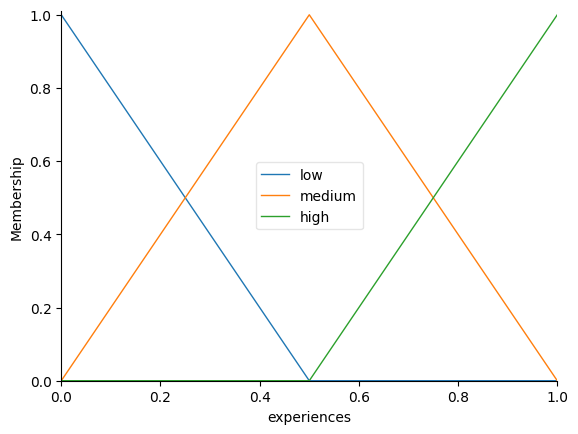

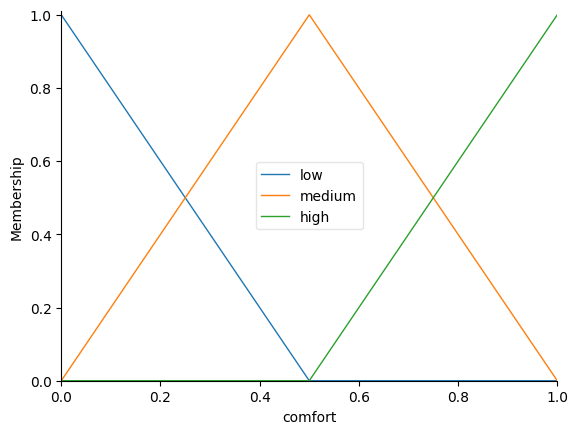

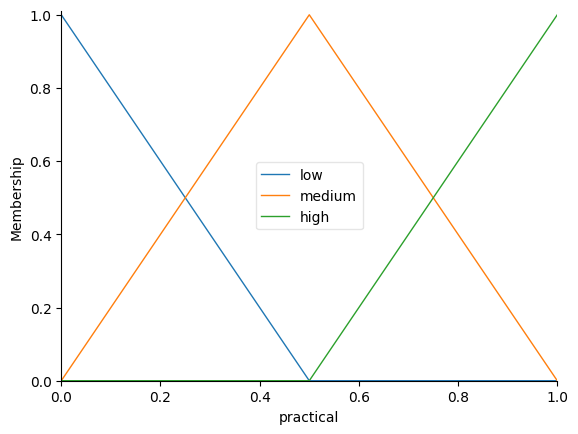

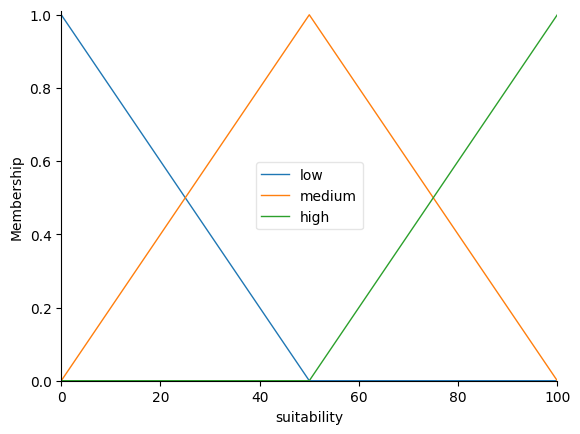

In [27]:
compatibility_universe = np.arange(0,1.001,0.01)
suitability_universe = np.arange(0,100.01,0.5)
experiences = ctrl.Antecedent(compatibility_universe,'experiences')
comfort = ctrl.Antecedent(compatibility_universe,'comfort')
practical = ctrl.Antecedent(compatibility_universe,'practical')
suitability = ctrl.Consequent(suitability_universe,'suitability')
suitability.defuzzify_method='centroid'
for var in (experiences,comfort,practical):
    var['low'] = fuzz.trimf(var.universe,[0,0,0.5])
    var['medium'] = fuzz.trimf(var.universe,[0,0.5,1])
    var['high'] = fuzz.trimf(var.universe,[0.5,1,1])
suitability['low'] = fuzz.trimf(suitability.universe,[0,0,50])
suitability['medium'] = fuzz.trimf(suitability.universe,[0,50,100])
suitability['high'] = fuzz.trimf(suitability.universe,[50,100,100])

# Classroom visualizations
experiences.view()
comfort.view()
practical.view()
suitability.view()
plt.show()

## 4. Fuzzy IF–THEN rules

The rules are constructed using `ctrl.Rule`, exactly as in the classroom examples. The 27-rule grid ensures coverage across every combination of *low/medium/high* for the three group inputs. **The consequent policy is an explicit modeling hypothesis**; it is not copied from an empirically validated tourism rule base. In particular, a low practical score prevents a high output category.

In [28]:
# Two rules written explicitly, in the course style.
rule_all_high=ctrl.Rule(experiences['high'] & comfort['high'] & practical['high'],
                        suitability['high'],label='all_high')
rule_all_low=ctrl.Rule(experiences['low'] & comfort['low'] & practical['low'],
                       suitability['low'],label='all_low')

levels=('low','medium','high')
rule_list=[rule_all_high,rule_all_low]
rule_table=[]
for e,c,p in itertools.product(range(3),repeat=3):
    result=int(np.floor((e+c+p)/3+0.5))
    if p==0:
        result=min(result,1)
    rule_table.append({'experiences':levels[e], 'comfort':levels[c],
                       'practical':levels[p], 'suitability':levels[result]})
    if (e,c,p) in ((2,2,2),(0,0,0)):
        continue
    rule_list.append(ctrl.Rule(
        experiences[levels[e]] & comfort[levels[c]] & practical[levels[p]],
        suitability[levels[result]],
        label=f'exp_{levels[e]}_comfort_{levels[c]}_practical_{levels[p]}'))
assert len(rule_list)==27
sillage_ctrl=ctrl.ControlSystem(rule_list)
print('Mamdani IF–THEN rules:',len(rule_list))
display(pd.DataFrame(rule_table))

Mamdani IF–THEN rules: 27


,experiences,comfort,practical,suitability
0,low,low,low,low
1,low,low,medium,low
2,low,low,high,medium
3,low,medium,low,low
4,low,medium,medium,medium
5,low,medium,high,medium
6,low,high,low,medium
7,low,high,medium,medium
8,low,high,high,medium
9,medium,low,low,low


## 5. Run Mamdani simulations and rank cities

This is a **provisional, incomplete-data ranking** when categories or costs are missing. Diagnostic columns show which themes contributed; the budget is only marked verified when its cost is available and comparable. The existing seven scenarios are used unchanged.

In [29]:
def grouped_scores(details):
    matches,coverage={},{}
    for group,themes in THEME_GROUPS.items():
        matches[group]=weighted_available([(details[t]['compatibility'],details[t]['weight'])
                                           for t in themes])
        coverage[group]=sum(pd.notna(details[t]['compatibility']) for t in themes)
    return matches,coverage


def rank_destinations(scenario_name,data=None):
    if scenario_name not in scenario_names:
        raise KeyError(scenario_name)
    data=cities if data is None else data  # cities_selected drops new category columns
    ranking,diagnostics=[],[]
    for _,city_series in data.iterrows():
        city=city_series.to_dict()
        details=compare_traveler_destination(scenario_name,city)
        group,coverage=grouped_scores(details)
        budget_status=details['t18']['status']
        complete=sum(pd.notna(x['compatibility']) for x in details.values())
        partial=[t for t,x in details.items() if x['status'].startswith('partial_')]
        rec={'Scenario':scenario_name,'City':city['City'],'themes_scored':complete,
             'themes_missing':19-complete,'themes_partial':', '.join(partial),
             'budget_status':budget_status,
             **{g+'_match':v for g,v in group.items()},
             **{g+'_coverage':v for g,v in coverage.items()}}
        if budget_status == 'budget:excluded':
            rec.update(suitability_score=np.nan,status='excluded_over_budget')
        elif any(pd.isna(v) for v in group.values()):
            rec.update(suitability_score=np.nan,status='insufficient_data')
        else:
            sim=ctrl.ControlSystemSimulation(sillage_ctrl)
            for g,v in group.items(): sim.input[g]=float(v)
            sim.compute()
            rec['suitability_score']=float(sim.output['suitability'])
            if budget_status=='budget:unknown':
                rec['status']='provisional_budget_unknown'
            elif complete<19 or partial:
                rec['status']='provisional_partial_data'
            else:
                rec['status']='complete_data'
        ranking.append(rec)
        for t,x in details.items():
            diagnostics.append({'Scenario':scenario_name,'City':city['City'],
                                'Theme':t,'Name':THEME_NAMES[t],**x})
    df=pd.DataFrame(ranking).sort_values('suitability_score',ascending=False,na_position='last')
    return df.reset_index(drop=True),pd.DataFrame(diagnostics)

all_rankings=[]
for name in scenario_names:
    ranking,diagnostics=rank_destinations(name)
    all_rankings.append(ranking)
    print('\n'+name)
    display(ranking[['City','suitability_score','themes_scored','themes_missing','status']].head(3))
rankings_df=pd.concat(all_rankings,ignore_index=True)
assert rankings_df['Scenario'].nunique()==7
print('Scenarios evaluated:',rankings_df['Scenario'].nunique())


Adventure Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Istanbul,56.419220,15,4,provisional_budget_unknown
1,Rome,53.056129,15,4,provisional_budget_unknown
2,Paris,52.356935,15,4,provisional_budget_unknown



Relaxation Lover


,City,suitability_score,themes_scored,themes_missing,status
0,Zurich,60.792938,15,4,provisional_budget_unknown
1,Copenhagen,53.981805,15,4,provisional_budget_unknown
2,Vienna,53.981805,15,4,provisional_budget_unknown



Food Explorer


,City,suitability_score,themes_scored,themes_missing,status
0,Paris,61.969584,15,4,provisional_budget_unknown
1,London,59.191099,15,4,provisional_budget_unknown
2,Athens,57.014643,15,4,provisional_budget_unknown


... (5 outputs left out)

,City,suitability_score,themes_scored,themes_missing,status
0,Helsinki,61.849013,15,4,provisional_budget_unknown
1,Stockholm,61.849013,15,4,provisional_budget_unknown
2,Zurich,58.663382,15,4,provisional_budget_unknown



Adventure Preference Change


,City,suitability_score,themes_scored,themes_missing,status
0,Paris,55.319644,15,4,provisional_budget_unknown
1,Rome,55.235153,15,4,provisional_budget_unknown
2,Istanbul,53.873553,15,4,provisional_budget_unknown


Scenarios evaluated: 7


## 6. Inspect individual themes and test sensitivity

The audit is indispensable: one overall score does not show which assumptions or missing data drove it. The seven scenarios are **synthetic tests**, not user validation.

Example scenario: Adventure Lover — city: Istanbul


,Theme,Name,compatibility,weight,status
722,t1,Change of Scenery,1.000000,1.000000,level
723,t2,Food / Gastronomy,1.000000,0.447500,importance_weighted_benefit
724,t3,Authenticity,NaN,1.000000,missing_or_unspecified_category
725,t4,Relaxation,0.792308,1.000000,level
726,t6,Must-see Landmarks,1.000000,0.433333,importance_weighted_benefit
727,t7,Infrastructure,0.895833,1.000000,tolerance
728,t8,Drinking Water / Hygiene,0.625000,1.000000,tolerance
729,t12,Unique Experiences,1.000000,0.974500,importance_weighted_benefit
730,t13,Beautiful Landscapes,0.375000,0.915000,partial_P_only_missing_T_categories
731,t14,Travel Pace,0.038462,1.000000,level


Adventure Lover → Adventurer Seeking Relaxation: max |Δ score| = 2.963
Adventure Lover → Adventure Preference Change: max |Δ score| = 2.963
Balanced Traveler → Budget-Constrained Traveler: max |Δ score| = 0.000


c:\Users\aurel\OneDrive\Documents\Ecole\Unine\Master\S3\Fuzzy Sets and Systems 1\Project\Fuzzy_Set_1_Projet\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


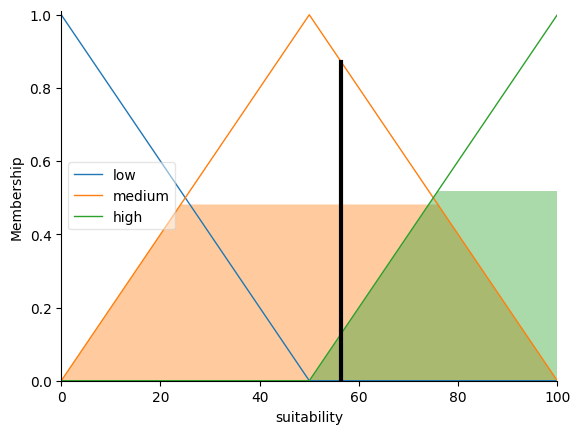

In [30]:
example_name='Adventure Lover'
first_rank,first_details=rank_destinations(example_name)
first_city=first_rank.iloc[0]['City']
print('Example scenario:',example_name,'— city:',first_city)
display(first_details[first_details['City']==first_city][['Theme','Name','compatibility','weight','status']])

# Quick diagnostics for the three controlled scenario comparisons.
for a,b in [('Adventure Lover','Adventurer Seeking Relaxation'),
            ('Adventure Lover','Adventure Preference Change'),
            ('Balanced Traveler','Budget-Constrained Traveler')]:
    a_rank,_=rank_destinations(a)
    b_rank,_=rank_destinations(b)
    merged=a_rank[['City','suitability_score']].merge(
        b_rank[['City','suitability_score']],on='City',suffixes=('_before','_after'))
    differences=(merged['suitability_score_after']-merged['suitability_score_before']).abs()
    print(f'{a} → {b}: max |Δ score| = {differences.max():.3f}'
          if differences.notna().any() else f'{a} → {b}: scores unavailable')

# Optional class-style visualization for a single simulated city:
row=first_rank.iloc[0]
if pd.notna(row['suitability_score']):
    sim=ctrl.ControlSystemSimulation(sillage_ctrl)
    for group in THEME_GROUPS:
        sim.input[group]=float(row[group+'_match'])
    sim.compute()
    suitability.view(sim=sim)
    plt.show()

### Sources used for this implementation

- `01_FuzzyControlSystem.ipynb` — `skfuzzy.control` workflow, variables, IF–THEN rules, control system and centroid defuzzification.
- `03_FuzzyVacationPlanner.ipynb` — separate personality and current-trip inputs, `trimf`, rule simulation and output visualization.
- `02_FuzzyClustering.ipynb` — illustrates fuzzy memberships, **not used** as the recommendation algorithm.
- `03_Sillage_devoir_tuto.ipynb` — illustrative traveler–destination compatibility before fuzzy inference.
- `Sillage_fuzzy_model_evaluation.ipynb` and `Cities.csv` — unchanged group profiles, seven scenarios, 19 topics and current dataset.

Observations